# Violence Detection (3-class) with MobileNetV2 + LSTM — Colab

Trains a **MobileNetV2 (frozen, ImageNet) + LSTM** video classifier on the
[SCVD dataset](https://www.kaggle.com/datasets/toluwaniaremu/smartcity-cctv-violence-detection-dataset-scvd)
for 3 classes: **Normal, Violence, Weaponized**.

**Actual dataset layout after unzipping (as confirmed by inspecting the download):**
```
/content/scvd_dataset/SCVD/
    SCVD_converted/
        Train/
            Normal/       <- video files
            Violence/      <- video files
            Weaponized/    <- video files
        Test/
            Normal/
            Violence/
            Weaponized/
    SCVD_converted_sec_split/
        Train/ ...
        Test/ ...
```
The dataset ships its own Train/Test split already, so this notebook uses that
directly (`SCVD_converted/Train` for training, `SCVD_converted/Test` for
validation) — no extra splitting needed. Set `DATASET_VARIANT` in step 4 to
switch to `SCVD_converted_sec_split` if you'd rather use that version.

**Steps:**
1. Install dependencies
2. Download + unzip the dataset from Kaggle
3. Mount Google Drive (only used to save the trained model/checkpoints)
4. Set paths, build `(path, label)` lists from the existing Train/Test folders
5. Frame sampling + augmentation
6. `tf.data` pipeline
7. Build MobileNetV2 + LSTM model
8. Train
9. Accuracy / loss curves
10. Confusion matrix + classification report
11. Save model


## 1. Install dependencies

In [ ]:
!pip install -q kaggle opencv-python-headless scikit-learn seaborn


## 2. Download and unzip the dataset from Kaggle

You'll need a Kaggle API token: go to your Kaggle account -> **Settings** -> **API**
-> **Create New Token**, which downloads a `kaggle.json` file. Run this cell and
upload that file when prompted.


In [1]:
from google.colab import files
import os

print("Upload your kaggle.json (Kaggle account -> Settings -> API -> Create New Token)")
uploaded = files.upload()   # pick your kaggle.json when prompted

os.makedirs('/root/.kaggle', exist_ok=True)
!cp kaggle.json /root/.kaggle/kaggle.json
!chmod 600 /root/.kaggle/kaggle.json


Upload your kaggle.json (Kaggle account -> Settings -> API -> Create New Token)


Saving kaggle.json to kaggle.json


In [2]:
!kaggle datasets download -d toluwaniaremu/smartcity-cctv-violence-detection-dataset-scvd -p /content/scvd_raw

import zipfile
import pathlib

zip_path = next(pathlib.Path('/content/scvd_raw').glob('*.zip'))
EXTRACT_DIR = pathlib.Path('/content/scvd_dataset')

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(EXTRACT_DIR)

print("Extracted to:", EXTRACT_DIR)


Dataset URL: https://www.kaggle.com/datasets/toluwaniaremu/smartcity-cctv-violence-detection-dataset-scvd
License(s): CC-BY-NC-SA-4.0
100% 1.03G/1.03G [00:11<00:00, 97.2MB/s]

Extracted to: /content/scvd_dataset


## 3. Mount Google Drive (used only to save the trained model)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


## 4. Set paths and read the existing Train / Test split

`CLASS_NAMES` order fixes the label ids (`Normal`=0, `Violence`=1, `Weaponized`=2,
since that's already alphabetical order) — keep track of this for inference later.


In [3]:
import pathlib
import random

EXTRACT_ROOT = pathlib.Path("/content/scvd_dataset/SCVD")

# "SCVD_converted" (full clips) or "SCVD_converted_sec_split" (clips split into seconds)
DATASET_VARIANT = "SCVD_converted"

DATASET_DIR = EXTRACT_ROOT / DATASET_VARIANT
CLASS_NAMES = ["Normal", "Violence", "Weaponized"]
VIDEO_EXTS = (".avi", ".mp4", ".mov", ".mkv")

CLASS_TO_ID = {name: idx for idx, name in enumerate(CLASS_NAMES)}
print("Class -> id mapping:", CLASS_TO_ID)


def build_pairs(split_dir, class_names):
    pairs = []
    for cls in class_names:
        cls_path = split_dir / cls
        if not cls_path.exists():
            print(f"Warning: '{cls_path}' does not exist. Skipping.")
            continue
        files = [f for f in cls_path.iterdir() if f.is_file() and f.suffix.lower() in VIDEO_EXTS]
        if not files:
            print(f"Warning: no video files found in '{cls_path}'.")
        pairs += [(f, cls) for f in files]
    return pairs


train_pairs = build_pairs(DATASET_DIR / "Train", CLASS_NAMES)
val_pairs   = build_pairs(DATASET_DIR / "Test", CLASS_NAMES)

random.shuffle(train_pairs)
random.shuffle(val_pairs)

print("Train videos:", len(train_pairs), "| Val (Test) videos:", len(val_pairs))


Class -> id mapping: {'Normal': 0, 'Violence': 1, 'Weaponized': 2}
Train videos: 399 | Val (Test) videos: 82


## 6. Imports

In [4]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import confusion_matrix, classification_report

print("TF version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))


TF version: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 7. Frame sampling + augmentation

`sample_frame_indices` picks `n_frames` indices spread across the whole video
(uniform sampling), with small random per-segment jitter during training for
temporal augmentation — this is more robust to variable-length CCTV clips than
a fixed stride.

`augment_frames` applies the same random flip to every frame in a clip plus
per-clip brightness/contrast/saturation jitter, so augmentation stays temporally
consistent across the clip (not a different random look per frame).


In [5]:
def format_frame(frame_bgr, output_size):
    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    frame = tf.image.convert_image_dtype(frame_rgb, tf.float32)
    frame = tf.image.resize_with_pad(frame, *output_size)
    return frame.numpy()


def sample_frame_indices(video_length, n_frames, training=False):
    if video_length <= 1:
        return np.zeros(n_frames, dtype=int)

    if video_length <= n_frames:
        return np.linspace(0, video_length - 1, n_frames).astype(int)

    if training:
        segment_len = video_length / n_frames
        idx = [int(i * segment_len + random.uniform(0, segment_len)) for i in range(n_frames)]
        idx = np.clip(idx, 0, video_length - 1)
    else:
        idx = np.linspace(0, video_length - 1, n_frames).astype(int)

    return idx


def frames_from_video_file(video_path, n_frames, output_size=(160, 160), training=False):
    src = cv2.VideoCapture(str(video_path))
    video_length = int(src.get(cv2.CAP_PROP_FRAME_COUNT))
    indices = sample_frame_indices(video_length, n_frames, training)

    result = []
    for idx in indices:
        src.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ret, frame = src.read()
        if ret:
            result.append(format_frame(frame, output_size))
        else:
            result.append(result[-1] if result else np.zeros((*output_size, 3), dtype=np.float32))
    src.release()

    return np.array(result)


def augment_frames(frames):
    frames = tf.convert_to_tensor(frames)

    if tf.random.uniform([]) > 0.5:
        frames = tf.image.flip_left_right(frames)

    frames = tf.image.random_brightness(frames, max_delta=0.15)
    frames = tf.image.random_contrast(frames, lower=0.85, upper=1.15)
    frames = tf.image.random_saturation(frames, lower=0.85, upper=1.15)
    frames = tf.clip_by_value(frames, 0.0, 1.0)

    return frames.numpy()


## 8. Frame generator + `tf.data` pipeline

In [6]:
RESOLUTION = 160     # MobileNetV2 works well at 160 or 224; 160 is lighter for Colab
NUM_FRAMES = 20
BATCH_SIZE = 8

class FrameGenerator:
    def __init__(self, pairs, n_frames, resolution, training=False):
        self.pairs = pairs
        self.n_frames = n_frames
        self.resolution = resolution
        self.training = training

    def __call__(self):
        pairs = list(self.pairs)
        if self.training:
            random.shuffle(pairs)

        for path, name in pairs:
            frames = frames_from_video_file(
                path, self.n_frames, (self.resolution, self.resolution), self.training
            )
            if self.training:
                frames = augment_frames(frames)
            label = CLASS_TO_ID[name]
            yield frames, label


output_signature = (
    tf.TensorSpec(shape=(NUM_FRAMES, RESOLUTION, RESOLUTION, 3), dtype=tf.float32),
    tf.TensorSpec(shape=(), dtype=tf.int16),
)

train_ds = tf.data.Dataset.from_generator(
    FrameGenerator(train_pairs, NUM_FRAMES, RESOLUTION, training=True),
    output_signature=output_signature
)
val_ds = tf.data.Dataset.from_generator(
    FrameGenerator(val_pairs, NUM_FRAMES, RESOLUTION, training=False),
    output_signature=output_signature
)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().batch(BATCH_SIZE).prefetch(AUTOTUNE)
val_ds   = val_ds.cache().batch(BATCH_SIZE).prefetch(AUTOTUNE)

for f, l in train_ds.take(1):
    print("Batch frames shape:", f.shape, "| batch labels:", l.numpy())


Batch frames shape: (8, 20, 160, 160, 3) | batch labels: [0 0 0 1 1 0 0 0]


## 9. Build the MobileNetV2 + LSTM model

`TimeDistributed(MobileNetV2)` applies the (frozen, ImageNet-pretrained)
MobileNetV2 to every frame in the clip independently to get per-frame feature
vectors, then an `LSTM` models how those features change over time, followed
by dense layers for the final 3-way classification.


In [7]:
def build_mobilenet_lstm(n_frames, resolution, num_classes):
    mobilenet = tf.keras.applications.MobileNetV2(
        include_top=False, weights='imagenet', pooling='avg',
        input_shape=(resolution, resolution, 3)
    )
    mobilenet.trainable = False  # freeze the CNN backbone

    frame_input = tf.keras.Input(shape=(n_frames, resolution, resolution, 3))
    x = tf.keras.layers.TimeDistributed(mobilenet)(frame_input)
    x = tf.keras.layers.LSTM(128, return_sequences=False)(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    x = tf.keras.layers.Dense(64, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax')(x)

    return tf.keras.Model(frame_input, outputs, name='mobilenet_lstm')


model = build_mobilenet_lstm(NUM_FRAMES, RESOLUTION, num_classes=len(CLASS_NAMES))
model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenet_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 20, 160, 160,   │             0 │
│                                 │ 3)                     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 20, 1280)       │     2,257,984 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       721,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,987,843 (11.40 MB)

 Trainable params: 729,859 (2.78 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 10. Compile

In [8]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


## 11. Callbacks

In [9]:
checkpoint_path = '/content/drive/MyDrive/mobilenet_lstm_violence_best.keras'

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(checkpoint_path, monitor='val_accuracy', save_best_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6),
]


## 12. Train

In [10]:
EPOCHS = 30

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1,
)


Epoch 1/30
     50/Unknown 336s 5s/step - accuracy: 0.3925 - loss: 1.1567

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


50/50 ━━━━━━━━━━━━━━━━━━━━ 413s 7s/step - accuracy: 0.4261 - loss: 1.1016 - val_accuracy: 0.5976 - val_loss: 0.9929 - learning_rate: 1.0000e-04
Epoch 2/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 257ms/step - accuracy: 0.4912 - loss: 1.0099 - val_accuracy: 0.5976 - val_loss: 0.9535 - learning_rate: 1.0000e-04
Epoch 3/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 262ms/step - accuracy: 0.5689 - loss: 0.9408 - val_accuracy: 0.5854 - val_loss: 0.9376 - learning_rate: 1.0000e-04
Epoch 4/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 26s 529ms/step - accuracy: 0.5564 - loss: 0.8881 - val_accuracy: 0.7317 - val_loss: 0.9217 - learning_rate: 1.0000e-04
Epoch 5/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 264ms/step - accuracy: 0.6140 - loss: 0.8301 - val_accuracy: 0.6463 - val_loss: 0.9187 - learning_rate: 1.0000e-04
Epoch 6/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 268ms/step - accuracy: 0.6466 - loss: 0.7718 - val_accuracy: 0.6220 - val_loss: 0.8944 - learning_rate: 1.0000e-04
Epoch 7/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 263ms/step - accuracy: 0.6817

## 13. Accuracy / loss curves

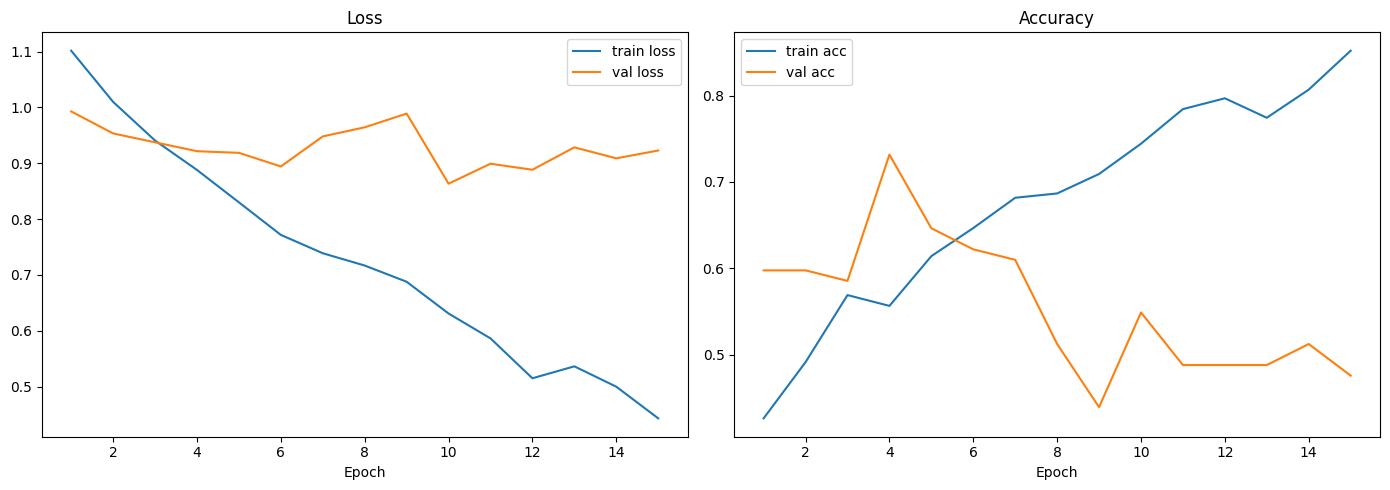

In [11]:
def plot_history(history):
    h = history.history
    epochs = range(1, len(h['loss']) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(epochs, h['loss'], label='train loss')
    axes[0].plot(epochs, h['val_loss'], label='val loss')
    axes[0].set_title('Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].legend()

    axes[1].plot(epochs, h['accuracy'], label='train acc')
    axes[1].plot(epochs, h['val_accuracy'], label='val acc')
    axes[1].set_title('Accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

plot_history(history)


## 14. Confusion matrix + classification report

11/11 ━━━━━━━━━━━━━━━━━━━━ 46s 2s/step


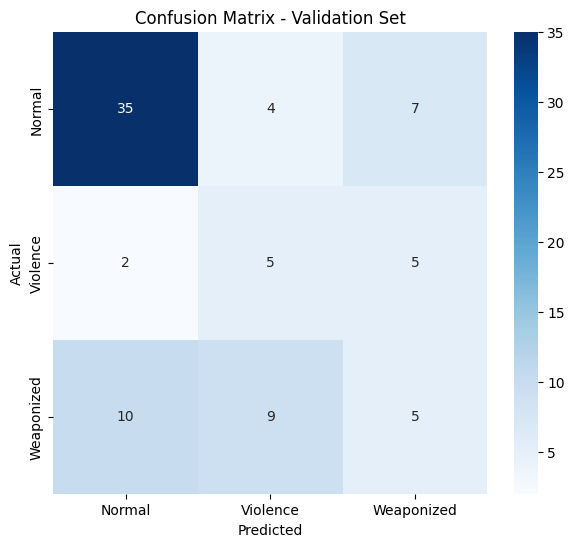

              precision    recall  f1-score   support

      Normal       0.74      0.76      0.75        46
    Violence       0.28      0.42      0.33        12
  Weaponized       0.29      0.21      0.24        24

    accuracy                           0.55        82
   macro avg       0.44      0.46      0.44        82
weighted avg       0.54      0.55      0.54        82



In [12]:
def get_actual_predicted_labels(dataset, model):
    actual = []
    for _, labels in dataset.unbatch():
        actual.append(labels.numpy())
    actual = np.array(actual)

    probs = model.predict(dataset, verbose=1)
    predicted = np.argmax(probs, axis=1)
    return actual, predicted


actual, predicted = get_actual_predicted_labels(val_ds, model)

cm = confusion_matrix(actual, predicted)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='g', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cmap='Blues')
plt.title('Confusion Matrix - Validation Set')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

print(classification_report(actual, predicted, target_names=CLASS_NAMES))


## 15. Save final model

In [13]:
import datetime

save_path = f"/content/drive/MyDrive/mobilenet_lstm_violence_{datetime.datetime.now().strftime('%Y%m%d_%H%M')}.keras"
model.save(save_path)
print("Saved to:", save_path)
print("Best checkpoint also saved during training at:", checkpoint_path)


Saved to: /content/drive/MyDrive/mobilenet_lstm_violence_20260718_0917.keras
Best checkpoint also saved during training at: /content/drive/MyDrive/mobilenet_lstm_violence_best.keras
